In [1]:

# 전통적인 프로그래밍
# 사람이 직접 규칙을 설정합니다.

def predict_pass(study_hours):
    if study_hours >= 5:
        return "합격"
    else:
        return "불합격"

# 새로운 학생의 공부 시간
student_hours = 7

# 결과 출력
result = predict_pass(student_hours)

print("공부 시간:", student_hours)
print("예측 결과:", result)


공부 시간: 7
예측 결과: 합격


In [2]:

import numpy as np
from sklearn.tree import DecisionTreeClassifier

# 1. 데이터(Data): 학생들의 공부 시간
X = np.array([[1], [2], [3], [4],
              [5], [6], [7], [8]])

# 2. 정답(Answers): 불합격=0, 합격=1
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# 3. 머신러닝 모델 생성
model = DecisionTreeClassifier(random_state=42)

# 4. 데이터와 정답으로 규칙 학습
model.fit(X, y)

# 5. 새로운 학생의 합격 여부 예측
student_hours = np.array([[7]])
prediction = model.predict(student_hours)

print("공부 시간:", 7)
print("예측 결과:",
      "합격" if prediction[0] == 1 else "불합격")

# 6. 학습된 규칙 확인
from sklearn.tree import export_text

print(export_text(model,
                  feature_names=["study_hours"]))


공부 시간: 7
예측 결과: 합격
|--- study_hours <= 4.50
|   |--- class: 0
|--- study_hours >  4.50
|   |--- class: 1



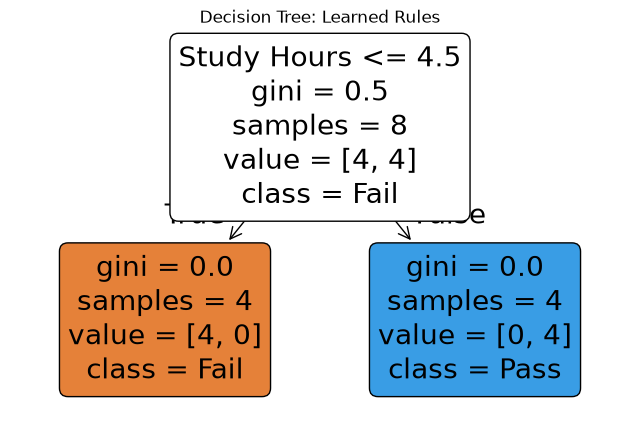

In [3]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(8, 5))

plot_tree(
    model,
    feature_names=["Study Hours"],
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree: Learned Rules")
plt.show()


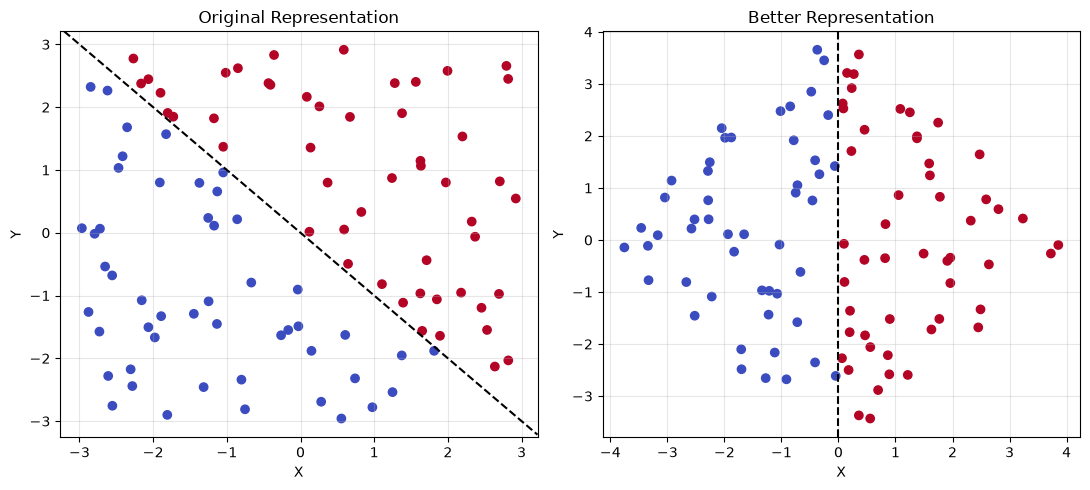

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# 1. 데이터 생성
np.random.seed(42)

n = 100
x = np.random.uniform(-3, 3, n)
y = np.random.uniform(-3, 3, n)

# 분류 정답: x + y가 0보다 크면 1
labels = (x + y > 0).astype(int)

# 2. 기존 표현
X_original = np.column_stack((x, y))

# 3. 새로운 표현: 좌표 변환
new_x = (x + y) / np.sqrt(2)
new_y = (y - x) / np.sqrt(2)

X_transformed = np.column_stack((new_x, new_y))

# 4. 시각화
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].scatter(x, y, c=labels, cmap="coolwarm")
axes[0].axline((0, 0), slope=-1,
               color="black", linestyle="--")
axes[0].set_title("Original Representation")

axes[1].scatter(new_x, new_y,
                c=labels, cmap="coolwarm")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Better Representation")

for ax in axes:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


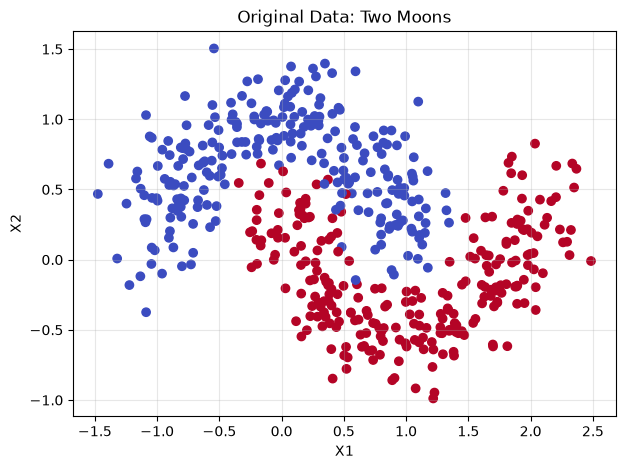

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# 1. 데이터 생성
X, y = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

# 2. 데이터 시각화
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")
plt.title("Original Data: Two Moons")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(alpha=0.3)
plt.show()


In [6]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42,
    stratify=y
)

# 머신러닝 모델
ml_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# 모델 학습
ml_model.fit(X_train, y_train)

# 예측
ml_pred = ml_model.predict(X_test)

# 정확도
ml_accuracy = accuracy_score(y_test, ml_pred)

print("Machine Learning Accuracy:", ml_accuracy)


Machine Learning Accuracy: 0.9


In [7]:

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 딥러닝 모델: 은닉층 3개
dl_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(32, 32, 16),
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=42
    )
)

# 모델 학습
dl_model.fit(X_train, y_train)

# 예측
dl_pred = dl_model.predict(X_test)

# 정확도
dl_accuracy = accuracy_score(y_test, dl_pred)

print("Deep Learning Accuracy:", dl_accuracy)


Deep Learning Accuracy: 0.9733333333333334


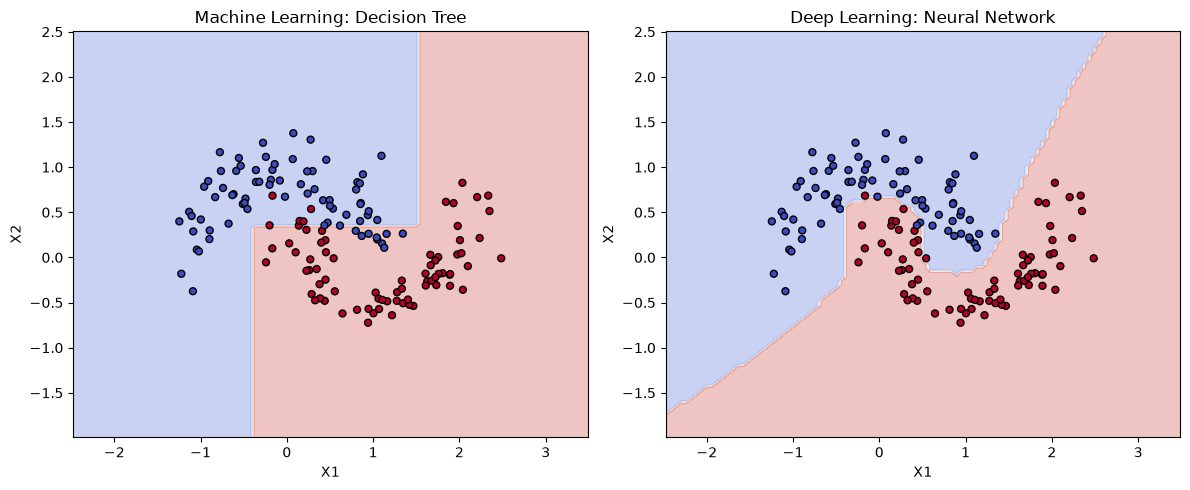

In [8]:

from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [ml_model, dl_model]
titles = ["Machine Learning: Decision Tree",
          "Deep Learning: Neural Network"]

for ax, model, title in zip(axes, models, titles):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X,
        response_method="predict",
        cmap="coolwarm",
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X_test[:, 0],
        X_test[:, 1],
        c=y_test,
        cmap="coolwarm",
        edgecolor="black",
        s=25
    )

    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")

plt.tight_layout()
plt.show()


In [9]:

from sklearn.neural_network import MLPClassifier

# 학습된 신경망 추출
neural_network = dl_model.named_steps["mlpclassifier"]

# 은닉층 구조 확인
print("Hidden Layers:", neural_network.hidden_layer_sizes)

# 각 층의 가중치 형태 출력
for i, weights in enumerate(neural_network.coefs_):
    print(f"Layer {i+1}: {weights.shape}")


Hidden Layers: (32, 32, 16)
Layer 1: (2, 32)
Layer 2: (32, 32)
Layer 3: (32, 16)
Layer 4: (16, 1)
